In [1]:
'''Develop automated report generation pipelines using Python and libraries like Jinja2 or Pandas-Profiling, 
integrating model evaluation outputs and visualizations into templated documents or dashboards.'''

'Develop automated report generation pipelines using Python and libraries like Jinja2 or Pandas-Profiling, \nintegrating model evaluation outputs and visualizations into templated documents or dashboards.'

In [2]:
# import libraries for reporting pipeline data processing and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import jinja2
import io
import base64
import datetime
import os
import json
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from IPython.display import display, HTML, IFrame

In [3]:
# load pharmacy sales data and compute business kpis
df = pd.read_csv('global_pharmacy_sales_data.csv')
df['revenue'] = df['units_sold'] * df['unit_price']

summary_kpis = {
    'total_records': f"{len(df):,}",
    'total_units_sold': f"{int(df['units_sold'].sum()):,}",
    'total_revenue': f"${df['revenue'].sum():,.2f}",
    'average_unit_price': f"${df['unit_price'].mean():.2f}",
    'top_category': str(df.groupby('category')['revenue'].sum().idxmax()),
    'top_region': str(df.groupby('region')['revenue'].sum().idxmax()),
    'top_medicine': str(df.groupby('medicine')['revenue'].sum().idxmax()),
    'covid_period_share': f"{(df['covid_flag'].mean() * 100):.1f}%"
}

category_breakdown = df.groupby('category').agg(
    total_units=('units_sold', 'sum'),
    total_revenue=('revenue', 'sum'),
    avg_price=('unit_price', 'mean')
).reset_index()
category_breakdown['total_revenue_formatted'] = category_breakdown['total_revenue'].apply(lambda x: f"${x:,.2f}")
category_breakdown['total_units_formatted'] = category_breakdown['total_units'].apply(lambda x: f"{x:,}")

for k, v in summary_kpis.items():
    print(f"{k}: {v}")

total_records: 177,990
total_units_sold: 79,724,186
total_revenue: $4,190,812,220.72
average_unit_price: $52.55
top_category: Antipyretic
top_region: East Asia
top_medicine: Paracetamol
covid_period_share: 33.4%


In [4]:
# train predictive classification models and extract evaluation metrics
sample_df = df.sample(n=25000, random_state=42).copy()
feature_cols = ['units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'category']
x = pd.get_dummies(sample_df[feature_cols], drop_first=True)
y = sample_df['covid_flag']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

rf_model = RandomForestClassifier(n_estimators=60, max_depth=6, random_state=42)
rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)
rf_prob = rf_model.predict_proba(x_test)[:, 1]

lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(x_train, y_train)
lr_pred = lr_model.predict(x_test)
lr_prob = lr_model.predict_proba(x_test)[:, 1]

model_eval_list = [
    {
        'model_name': 'Random Forest Classifier',
        'accuracy': f"{accuracy_score(y_test, rf_pred):.4f}",
        'precision': f"{precision_score(y_test, rf_pred, zero_division=0):.4f}",
        'recall': f"{recall_score(y_test, rf_pred):.4f}",
        'f1_score': f"{f1_score(y_test, rf_pred):.4f}",
        'auc_roc': f"{roc_auc_score(y_test, rf_prob):.4f}"
    },
    {
        'model_name': 'Logistic Regression',
        'accuracy': f"{accuracy_score(y_test, lr_pred):.4f}",
        'precision': f"{precision_score(y_test, lr_pred, zero_division=0):.4f}",
        'recall': f"{recall_score(y_test, lr_pred):.4f}",
        'f1_score': f"{f1_score(y_test, lr_pred):.4f}",
        'auc_roc': f"{roc_auc_score(y_test, lr_prob):.4f}"
    }
]

feature_importances = pd.DataFrame({
    'feature': x.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False).head(5).to_dict(orient='records')

print('model evaluation metrics computed:')
print(model_eval_list)

model evaluation metrics computed:
[{'model_name': 'Random Forest Classifier', 'accuracy': '0.7554', 'precision': '0.7619', 'recall': '0.3904', 'f1_score': '0.5163', 'auc_roc': '0.8013'}, {'model_name': 'Logistic Regression', 'accuracy': '0.7546', 'precision': '0.7814', 'recall': '0.3694', 'f1_score': '0.5016', 'auc_roc': '0.7992'}]


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [5]:
# generate visual charts and encode as base64 images for template embedding
def get_chart_base64():
    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight')
    plt.close()
    buf.seek(0)
    return base64.b64encode(buf.read()).decode('utf-8')

df.groupby('category')['revenue'].sum().plot(kind='bar')
plt.title('revenue by category')
chart_category_b64 = get_chart_base64()

df.groupby('region')['units_sold'].sum().plot(kind='bar')
plt.title('units sold by region')
chart_region_b64 = get_chart_base64()

df['units_sold'].plot(kind='hist')
plt.title('units sold distribution')
chart_units_b64 = get_chart_base64()

df.groupby('medicine')['revenue'].sum().nlargest(5).plot(kind='bar')
plt.title('top 5 medicines by revenue')
chart_medicine_b64 = get_chart_base64()

print('four visual charts rendered and base64 encoded successfully')

four visual charts rendered and base64 encoded successfully


In [6]:
# define jinja2 html document template for dashboard reporting
dashboard_template_str = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Global Pharmacy Sales & Predictive Analytics Dashboard</title>
    <style>
        body { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Arial, sans-serif; margin: 0; padding: 20px; background-color: #f4f6f9; color: #333; }
        .dashboard-container { max-width: 1100px; margin: 0 auto; }
        .header-card { background: linear-gradient(135deg, #1e3c72 0%, #2a5298 100%); color: white; padding: 25px; border-radius: 8px; margin-bottom: 25px; box-shadow: 0 4px 6px rgba(0,0,0,0.1); }
        .header-card h1 { margin: 0 0 8px 0; font-size: 26px; }
        .header-card p { margin: 0; opacity: 0.9; font-size: 14px; }
        .kpi-grid { display: grid; grid-template-columns: repeat(auto-fit, minmax(220px, 1fr)); gap: 15px; margin-bottom: 25px; }
        .kpi-card { background: white; padding: 18px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.06); border-left: 4px solid #2a5298; }
        .kpi-label { font-size: 12px; color: #666; text-transform: uppercase; margin-bottom: 6px; }
        .kpi-value { font-size: 20px; font-weight: bold; color: #1e3c72; }
        .section-card { background: white; padding: 22px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.06); margin-bottom: 25px; }
        .section-title { margin-top: 0; margin-bottom: 15px; font-size: 18px; color: #1e3c72; border-bottom: 2px solid #eef2f7; padding-bottom: 8px; }
        table { width: 100%; border-collapse: collapse; margin-top: 10px; font-size: 14px; }
        th, td { border: 1px solid #e1e4e8; padding: 10px 12px; text-align: left; }
        th { background-color: #f8f9fa; color: #495057; font-weight: 600; }
        tr:nth-child(even) { background-color: #fcfcfc; }
        .chart-grid { display: grid; grid-template-columns: repeat(auto-fit, minmax(450px, 1fr)); gap: 20px; }
        .chart-card { background: #fafbfc; border: 1px solid #e1e4e8; border-radius: 6px; padding: 12px; text-align: center; }
        .chart-card img { max-width: 100%; height: auto; border-radius: 4px; }
        .badge { display: inline-block; padding: 4px 8px; border-radius: 4px; font-size: 12px; font-weight: bold; background: #e8f5e9; color: #2e7d32; }
    </style>
</head>
<body>
    <div class="dashboard-container">
        <div class="header-card">
            <h1>Global Pharmacy Sales & Predictive Analytics Dashboard</h1>
            <p>Automated Pipeline Report | Generated on: {{ generation_time }} | Status: <span class="badge">Production Ready</span></p>
        </div>

        <div class="kpi-grid">
            <div class="kpi-card">
                <div class="kpi-label">Total Transactions</div>
                <div class="kpi-value">{{ kpis.total_records }}</div>
            </div>
            <div class="kpi-card">
                <div class="kpi-label">Total Units Sold</div>
                <div class="kpi-value">{{ kpis.total_units_sold }}</div>
            </div>
            <div class="kpi-card">
                <div class="kpi-label">Total Sales Revenue</div>
                <div class="kpi-value">{{ kpis.total_revenue }}</div>
            </div>
            <div class="kpi-card">
                <div class="kpi-label">Average Unit Price</div>
                <div class="kpi-value">{{ kpis.average_unit_price }}</div>
            </div>
            <div class="kpi-card">
                <div class="kpi-label">Top Category</div>
                <div class="kpi-value">{{ kpis.top_category }}</div>
            </div>
            <div class="kpi-card">
                <div class="kpi-label">Top Region</div>
                <div class="kpi-value">{{ kpis.top_region }}</div>
            </div>
        </div>

        <div class="section-card">
            <h2 class="section-title">Model Evaluation Benchmark Outputs</h2>
            <table>
                <thead>
                    <tr>
                        <th>Algorithm</th>
                        <th>Accuracy</th>
                        <th>Precision</th>
                        <th>Recall</th>
                        <th>F1-Score</th>
                        <th>AUC-ROC</th>
                    </tr>
                </thead>
                <tbody>
                    {% for m in model_eval %}
                    <tr>
                        <td><strong>{{ m.model_name }}</strong></td>
                        <td>{{ m.accuracy }}</td>
                        <td>{{ m.precision }}</td>
                        <td>{{ m.recall }}</td>
                        <td>{{ m.f1_score }}</td>
                        <td>{{ m.auc_roc }}</td>
                    </tr>
                    {% endfor %}
                </tbody>
            </table>
        </div>

        <div class="section-card">
            <h2 class="section-title">Top Predictive Feature Importances (Random Forest)</h2>
            <table>
                <thead>
                    <tr><th>Feature Dimension</th><th>Relative Importance Score</th></tr>
                </thead>
                <tbody>
                    {% for item in feature_importances %}
                    <tr>
                        <td>{{ item.feature }}</td>
                        <td>{{ "%.4f"|format(item.importance) }}</td>
                    </tr>
                    {% endfor %}
                </tbody>
            </table>
        </div>

        <div class="section-card">
            <h2 class="section-title">Category Revenue & Volume Breakdown</h2>
            <table>
                <thead>
                    <tr>
                        <th>Product Category</th>
                        <th>Units Sold</th>
                        <th>Sales Revenue</th>
                        <th>Avg Unit Price</th>
                    </tr>
                </thead>
                <tbody>
                    {% for row in category_data %}
                    <tr>
                        <td><strong>{{ row.category }}</strong></td>
                        <td>{{ row.total_units_formatted }}</td>
                        <td>{{ row.total_revenue_formatted }}</td>
                        <td>${{ "%.2f"|format(row.avg_price) }}</td>
                    </tr>
                    {% endfor %}
                </tbody>
            </table>
        </div>

        <div class="section-card">
            <h2 class="section-title">Pipeline Visualizations & Analytical Charts</h2>
            <div class="chart-grid">
                <div class="chart-card">
                    <img src="data:image/png;base64,{{ charts.category }}" alt="Category Revenue" />
                </div>
                <div class="chart-card">
                    <img src="data:image/png;base64,{{ charts.region }}" alt="Regional Sales Volume" />
                </div>
                <div class="chart-card">
                    <img src="data:image/png;base64,{{ charts.units }}" alt="Units Sold Distribution" />
                </div>
                <div class="chart-card">
                    <img src="data:image/png;base64,{{ charts.medicine }}" alt="Top Medicines" />
                </div>
            </div>
        </div>
    </div>
</body>
</html>
"""
compiled_template = jinja2.Template(dashboard_template_str)
print('jinja2 html dashboard template compiled successfully')

jinja2 html dashboard template compiled successfully


In [7]:
# execute automated report rendering pipeline and save html document
current_timestamp = datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')

rendered_dashboard = compiled_template.render(
    generation_time=current_timestamp,
    kpis=summary_kpis,
    model_eval=model_eval_list,
    feature_importances=feature_importances,
    category_data=category_breakdown.to_dict(orient='records'),
    charts={
        'category': chart_category_b64,
        'region': chart_region_b64,
        'units': chart_units_b64,
        'medicine': chart_medicine_b64
    }
)

output_filepath = 'automated_pharmacy_dashboard.html'
with open(output_filepath, 'w', encoding='utf-8') as f:
    f.write(rendered_dashboard)

print(f'automated report pipeline completed successfully')
print(f'saved document to {output_filepath} ({os.path.getsize(output_filepath):,} bytes)')

automated report pipeline completed successfully
saved document to automated_pharmacy_dashboard.html (101,042 bytes)



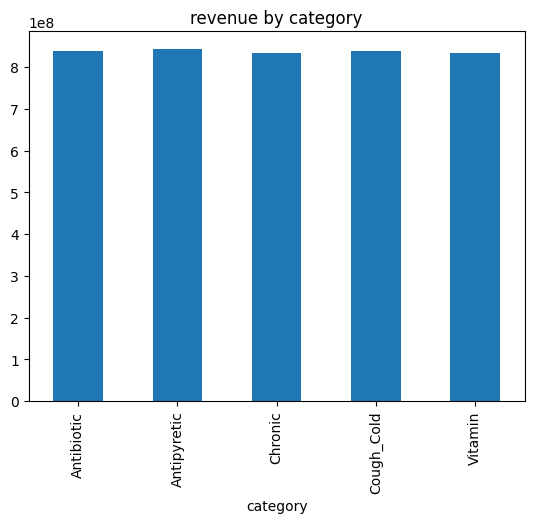
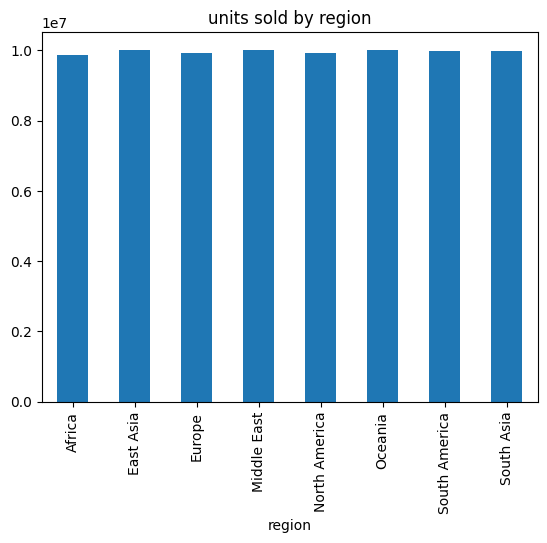
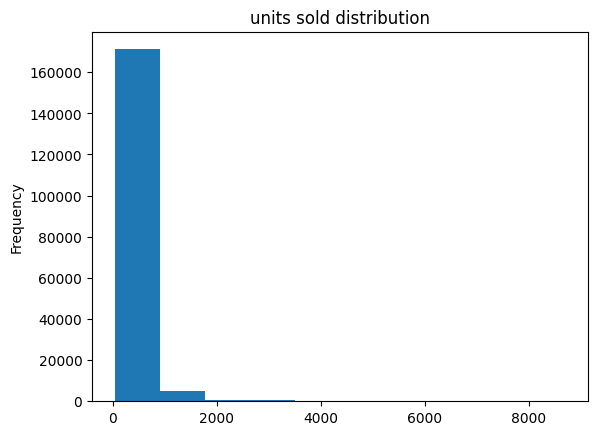
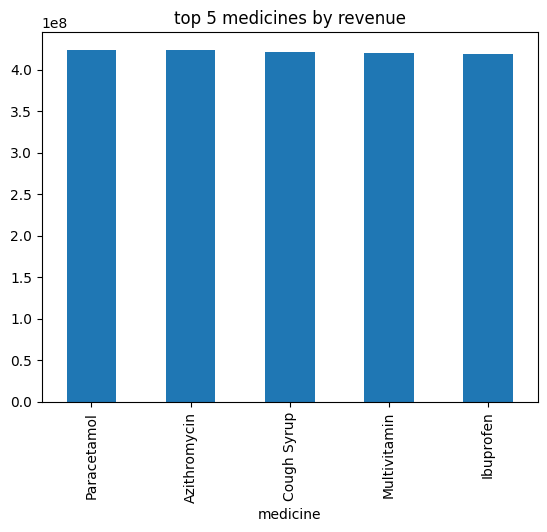

In [8]:
# preview rendered html dashboard report directly inside notebook
with open('automated_pharmacy_dashboard.html', 'r', encoding='utf-8') as f:
    dashboard_html = f.read()

display(HTML(dashboard_html))

In [9]:
# render interactive iframe preview inside notebook for standalone validation
display(IFrame('automated_pharmacy_dashboard.html', width='100%', height=700))

In [10]:
# export summary report data as json for automated pipeline integration
export_payload = {
    'generated_at': current_timestamp,
    'kpis': summary_kpis,
    'model_evaluations': model_eval_list,
    'top_features': feature_importances
}

with open('automated_report_metadata.json', 'w') as f:
    json.dump(export_payload, f, indent=2)

print('exported metadata to automated_report_metadata.json for downstream ingestion')

exported metadata to automated_report_metadata.json for downstream ingestion
